# Лабораторна робота №4
## Симуляція різних типів СМО за допомогою SimPy

**Мета:** Дослідження різнотипних СМО за допомогою SimPy

### Зміст лабораторної роботи

**Завдання:** Побудувати систему масового обслуговування (СМО) з втратами та без очікування

**Структура роботи:**

1. **Визначення вихідних даних** - розрахунок параметрів на основі прізвища
2. **Реалізація моделі в SimPy** - програмна реалізація з підтримкою двох типів розподілу
3. **Імітаційне моделювання** - запуск симуляції з 1200 заявками
4. **Дослідження параметрів** - вплив кількості пристроїв, часу обслуговування, типу розподілу
5. **Візуалізація результатів** - графіки, діаграми, аналіз
6. **Покрокове виконання** - детальне логування для перевірки коректності
7. **Висновки** - аналіз отриманих результатів

**Особливості реалізації:**
- Підтримка рівномірного та послідовного розподілу навантаження
- Детальна статистика по кожному пристрою
- Візуалізація часової діаграми подій (Gantt Chart)
- Логування всіх подій для покрокового аналізу


### Встановлення необхідних бібліотек

In [1]:
%pip install numpy pandas matplotlib seaborn simpy tabulate --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import simpy
import random
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
import sys

# Налаштування стилю графіків
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Налаштування логування
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)
handler = logging.StreamHandler(sys.stdout)
logger.addHandler(handler)

# Вихідні параметри
input1 = 12  # кількість букв у прізвищі
input2 = 5   # кількість голосних букв

total_requests = 100 * input1
num_devices = input2
distribution_type = 'uniform' if input1 % 2 == 0 else 'sequential'  # парне → рівномірний

interarrival_mean = 2.0
service_time_mean = 5.0

### Визначення вихідних даних

- **Кп** = кількість букв у прізвищі
- **Кг** = кількість голосних букв

**Параметри системи:**
- **Кількість заявок** = 100 × Кп = 100 × 12 = **1200 заявок**
- **Кількість обслуговуючих пристроїв** = Кг = **5 пристроїв**
- **Процедура розподілу**: Кп = 12 (парне) → **рівномірний розподіл** на всі пристрої
- **Тип системи**: M/M/c/c (СМО з відмовами та без очікування)
- **Вхідний потік**: Пуассонівський (експоненціальний розподіл між прибуттями)
- **Час обслуговування**: Експоненціальний розподіл
- **Місткість системи**: c (немає черги, при зайнятості всіх пристроїв - відмова)

### Реалізація моделі в SimPy

#### 1. Клас QueueingSystem (СМО з відмовами)

In [3]:
class QueueingSystem:
    """
    Система масового обслуговування з відмовами (M/M/c/c)
    Підтримує два типи розподілу навантаження:
    - Рівномірний (для парного Кп)
    - Послідовний (для непарного Кп)
    """
    def __init__(self, env, num_devices, service_time_mean, distribution_type, rng_service, debug=False):
        self.env = env
        self.num_devices = num_devices
        self.service_time_mean = service_time_mean
        self.distribution_type = distribution_type  # 'uniform' or 'sequential'
        self.rng_service = rng_service
        self.debug = debug
        
        # Створюємо окремі ресурси для кожного пристрою
        self.devices = [simpy.Resource(env, capacity=1) for _ in range(num_devices)]
        
        # Статистика
        self.requests_arrived = 0
        self.requests_served = 0
        self.requests_rejected = 0
        self.service_times = []
        self.device_stats = [0] * num_devices  # кількість обслужених заявок на кожному пристрої
        
        # Для покрокового виконання
        self.events_log = []
        
    def log_event(self, event_type, request_id, device_id=None, time=None):
        """Логування подій для покрокового аналізу"""
        if time is None:
            time = self.env.now
        event = {
            'time': round(time, 2),
            'type': event_type,
            'request_id': request_id,
            'device_id': device_id
        }
        self.events_log.append(event)
        if self.debug:
            msg = f"t={time:.2f} | Заявка #{request_id}"
            if event_type == 'arrival':
                logger.info(f"{msg} | ПРИБУТТЯ")
            elif event_type == 'accepted':
                logger.info(f"{msg} | ПРИЙНЯТО на пристрій {device_id}")
            elif event_type == 'rejected':
                logger.info(f"{msg} | ВІДМОВЛЕНО (всі пристрої зайняті)")
            elif event_type == 'service_start':
                logger.info(f"{msg} | ПОЧАТОК обслуговування на пристрої {device_id}")
            elif event_type == 'service_end':
                logger.info(f"{msg} | ЗАВЕРШЕНО обслуговування на пристрої {device_id}")
    
    def serve_request(self, request_id, device_id):
        """Процес обслуговування заявки"""
        self.log_event('service_start', request_id, device_id)
        service_time = float(self.rng_service.exponential(self.service_time_mean))
        yield self.env.timeout(service_time)
        self.service_times.append(service_time)
        self.device_stats[device_id] += 1
        self.log_event('service_end', request_id, device_id)
    
    def try_allocate_device(self):
        """
        Спроба виділити пристрій для заявки
        Повертає (device_id, request_object) або (None, None)
        """
        if self.distribution_type == 'uniform':
            # Рівномірний розподіл: випадковий вибір серед вільних
            free_devices = [(i, dev) for i, dev in enumerate(self.devices) if len(dev.queue) == 0 and dev.count == 0]
            if free_devices:
                device_id, device = random.choice(free_devices)
                req = device.request()
                return device_id, req
        else:  # sequential
            # Послідовний пошук: спроба 1→2→3→...→n
            for device_id, device in enumerate(self.devices):
                if len(device.queue) == 0 and device.count == 0:
                    req = device.request()
                    return device_id, req
        
        return None, None


def request_generator(env, system, total_requests, interarrival_time_mean, rng_arrival):
    """
    Генератор заявок
    """
    for request_id in range(1, total_requests + 1):
        # Міжприбуттєвий інтервал (експоненціальний розподіл)
        interarrival = float(rng_arrival.exponential(interarrival_time_mean))
        yield env.timeout(interarrival)
        
        system.requests_arrived += 1
        system.log_event('arrival', request_id)
        
        # Спроба виділити пристрій
        device_id, req = system.try_allocate_device()
        
        if device_id is not None:
            # Заявка прийнята
            system.requests_served += 1
            system.log_event('accepted', request_id, device_id)
            
            # Запускаємо процес обслуговування
            env.process(handle_request_service(env, system, request_id, device_id, req))
        else:
            # Відмова (всі пристрої зайняті)
            system.requests_rejected += 1
            system.log_event('rejected', request_id)


def handle_request_service(env, system, request_id, device_id, req):
    """Обробка обслуговування заявки"""
    try:
        yield req
        yield env.process(system.serve_request(request_id, device_id))
    finally:
        system.devices[device_id].release(req)

#### 2. Функція запуску симуляції

In [4]:
def simulate_queueing_system(
    num_devices,
    total_requests,
    interarrival_time_mean,
    service_time_mean,
    distribution_type='uniform',
    debug=False,
    seed=None
):
    """
    Запуск симуляції СМО з відмовами
    
    Параметри:
    - num_devices: кількість обслуговуючих пристроїв
    - total_requests: загальна кількість заявок
    - interarrival_time_mean: середній час між прибуттям заявок
    - service_time_mean: середній час обслуговування
    - distribution_type: 'uniform' (рівномірний) або 'sequential' (послідовний)
    - debug: виводити покрокові події
    - seed: зерно для генератора випадкових чисел
    
    Повертає: словник з результатами симуляції та об'єкт системи
    """
    rng_arrival = np.random.default_rng(seed if seed is not None else None)
    rng_service = np.random.default_rng((seed + 1) if seed is not None else None)
    
    env = simpy.Environment()
    system = QueueingSystem(env, num_devices, service_time_mean, distribution_type, rng_service, debug)
    env.process(request_generator(env, system, total_requests, interarrival_time_mean, rng_arrival))
    env.run()
    
    # Розрахунок статистики
    arrived = system.requests_arrived
    served = system.requests_served
    rejected = system.requests_rejected
    rejection_rate = (rejected / arrived * 100) if arrived > 0 else 0.0
    avg_service_time = statistics.mean(system.service_times) if system.service_times else 0.0
    total_service_time = sum(system.service_times)
    simulation_time = env.now
    utilization = (total_service_time / (num_devices * simulation_time) * 100) if simulation_time > 0 else 0.0
    
    return {
        'Пристроїв': num_devices,
        'Прибуло заявок': arrived,
        'Обслужено': served,
        'Відмовлено': rejected,
        'Ймовірність відмови (%)': round(rejection_rate, 2),
        'Середній час обслуговування': round(avg_service_time, 2),
        'Завантаженість (%)': round(utilization, 2),
        'Час симуляції': round(simulation_time, 2),
        'Розподіл': distribution_type
    }, system

### Виконання імітаційного моделювання

#### 3. Симуляція з вихідними даними

In [5]:
logger.info(f"""ЛАБОРАТОРНА РОБОТА №4: СМО З ВІДМОВАМИ ТА БЕЗ ОЧІКУВАННЯ

ВИХІДНІ ДАНІ:
Кількість букв у прізвищі (Кп): {input1}
Кількість голосних букв (Кг): {input2}
Загальна кількість заявок: {total_requests}
Кількість пристроїв: {num_devices}
Тип розподілу: {'РІВНОМІРНИЙ (Кп парне)' if distribution_type == 'uniform' else 'ПОСЛІДОВНИЙ (Кп непарне)'}
Середній час між прибуттям: {interarrival_mean}
Середній час обслуговування: {service_time_mean}

ЗАПУСК СИМУЛЯЦІЇ
""")

result, system = simulate_queueing_system(
    num_devices=num_devices,
    total_requests=total_requests,
    interarrival_time_mean=interarrival_mean,
    service_time_mean=service_time_mean,
    distribution_type=distribution_type,
    debug=False,  # Без покрокового виводу для швидкості
    seed=42
)

logger.info("РЕЗУЛЬТАТИ МОДЕЛЮВАННЯ:\n" + "-" * 90)
for key, value in result.items():
    logger.info(f"{key}: {value}")

df_main_result = pd.DataFrame([result])
logger.info("\nТАБЛИЦЯ РЕЗУЛЬТАТІВ:")
logger.info(df_main_result.to_markdown(index=False))

ЛАБОРАТОРНА РОБОТА №4: СМО З ВІДМОВАМИ ТА БЕЗ ОЧІКУВАННЯ

ВИХІДНІ ДАНІ:
Кількість букв у прізвищі (Кп): 12
Кількість голосних букв (Кг): 5
Загальна кількість заявок: 1200
Кількість пристроїв: 5
Тип розподілу: РІВНОМІРНИЙ (Кп парне)
Середній час між прибуттям: 2.0
Середній час обслуговування: 5.0

ЗАПУСК СИМУЛЯЦІЇ

РЕЗУЛЬТАТИ МОДЕЛЮВАННЯ:
------------------------------------------------------------------------------------------
Пристроїв: 5
Прибуло заявок: 1200
Обслужено: 1118
Відмовлено: 82
Ймовірність відмови (%): 6.83
Середній час обслуговування: 5.01
Завантаженість (%): 46.32
Час симуляції: 2420.83
Розподіл: uniform

ТАБЛИЦЯ РЕЗУЛЬТАТІВ:
|   Пристроїв |   Прибуло заявок |   Обслужено |   Відмовлено |   Ймовірність відмови (%) |   Середній час обслуговування |   Завантаженість (%) |   Час симуляції | Розподіл   |
|------------:|-----------------:|------------:|-------------:|--------------------------:|------------------------------:|---------------------:|----------------:|:--------

#### 4. Детальна статистика по пристроях


In [6]:
logger.info("СТАТИСТИКА ПО ПРИСТРОЯХ")

device_data = []
for i, count in enumerate(system.device_stats):
    device_data.append({
        'Пристрій': f'Пристрій {i}',
        'Обслужено заявок': count,
        'Відсоток від загальних': round(count / sum(system.device_stats) * 100, 2) if sum(system.device_stats) > 0 else 0
    })

df_devices = pd.DataFrame(device_data)
logger.info("\n" + df_devices.to_markdown(index=False))

logger.info("\nАНАЛІЗ РОЗПОДІЛУ:")
logger.info(f"Мінімум обслужень на пристрій: {min(system.device_stats)}")
logger.info(f"Максимум обслужень на пристрій: {max(system.device_stats)}")
logger.info(f"Середнє обслужень на пристрій: {statistics.mean(system.device_stats):.2f}")
logger.info(f"Стандартне відхилення: {statistics.stdev(system.device_stats):.2f}" if len(system.device_stats) > 1 else "Стандартне відхилення: N/A")

if distribution_type == 'uniform':
    logger.info(f"Рівномірність розподілу: {'Висока' if max(system.device_stats) - min(system.device_stats) < 50 else 'Середня' if max(system.device_stats) - min(system.device_stats) < 100 else 'Низька'}")


СТАТИСТИКА ПО ПРИСТРОЯХ

| Пристрій   |   Обслужено заявок |   Відсоток від загальних |
|:-----------|-------------------:|-------------------------:|
| Пристрій 0 |                220 |                    19.68 |
| Пристрій 1 |                219 |                    19.59 |
| Пристрій 2 |                221 |                    19.77 |
| Пристрій 3 |                232 |                    20.75 |
| Пристрій 4 |                226 |                    20.21 |

АНАЛІЗ РОЗПОДІЛУ:
Мінімум обслужень на пристрій: 219
Максимум обслужень на пристрій: 232
Середнє обслужень на пристрій: 223.60
Стандартне відхилення: 5.41
Рівномірність розподілу: Висока


#### 5. Дослідження впливу параметрів


In [7]:
logger.info("ДОСЛІДЖЕННЯ 1: Вплив кількості пристроїв")

results_devices = []
for n_dev in range(2, 11):
    res, _ = simulate_queueing_system(
        num_devices=n_dev,
        total_requests=1200,
        interarrival_time_mean=2.0,
        service_time_mean=5.0,
        distribution_type='uniform',
        debug=False,
        seed=42
    )
    results_devices.append(res)

df_devices_impact = pd.DataFrame(results_devices)
logger.info(df_devices_impact[['Пристроїв', 'Обслужено', 'Відмовлено', 'Ймовірність відмови (%)', 'Завантаженість (%)']].to_markdown(index=False))

logger.info("\nДОСЛІДЖЕННЯ 2: Вплив часу обслуговування")

results_service = []
for svc_time in [2, 3, 5, 7, 10, 15]:
    res, _ = simulate_queueing_system(
        num_devices=5,
        total_requests=1200,
        interarrival_time_mean=2.0,
        service_time_mean=svc_time,
        distribution_type='uniform',
        debug=False,
        seed=42
    )
    results_service.append(res)

df_service_impact = pd.DataFrame(results_service)
logger.info(df_service_impact[['Середній час обслуговування', 'Обслужено', 'Відмовлено', 'Ймовірність відмови (%)', 'Завантаженість (%)']].to_markdown(index=False))

logger.info("\nДОСЛІДЖЕННЯ 3: Порівняння типів розподілу")

results_distribution = []
for dist_type in ['uniform', 'sequential']:
    res, _ = simulate_queueing_system(
        num_devices=5,
        total_requests=1200,
        interarrival_time_mean=2.0,
        service_time_mean=5.0,
        distribution_type=dist_type,
        debug=False,
        seed=42
    )
    results_distribution.append(res)

df_distribution = pd.DataFrame(results_distribution)
logger.info(df_distribution[['Розподіл', 'Обслужено', 'Відмовлено', 'Ймовірність відмови (%)', 'Завантаженість (%)']].to_markdown(index=False))

ДОСЛІДЖЕННЯ 1: Вплив кількості пристроїв
|   Пристроїв |   Обслужено |   Відмовлено |   Ймовірність відмови (%) |   Завантаженість (%) |
|------------:|------------:|-------------:|--------------------------:|---------------------:|
|           2 |         640 |          560 |                     46.67 |                65.27 |
|           3 |         867 |          333 |                     27.75 |                58.73 |
|           4 |        1018 |          182 |                     15.17 |                52.2  |
|           5 |        1118 |           82 |                      6.83 |                46.32 |
|           6 |        1156 |           44 |                      3.67 |                39.91 |
|           7 |        1184 |           16 |                      1.33 |                35.07 |
|           8 |        1194 |            6 |                      0.5  |                30.9  |
|           9 |        1199 |            1 |                      0.08 |                27.61 |

### Візуалізація результатів

#### 6. Графіки та діаграми


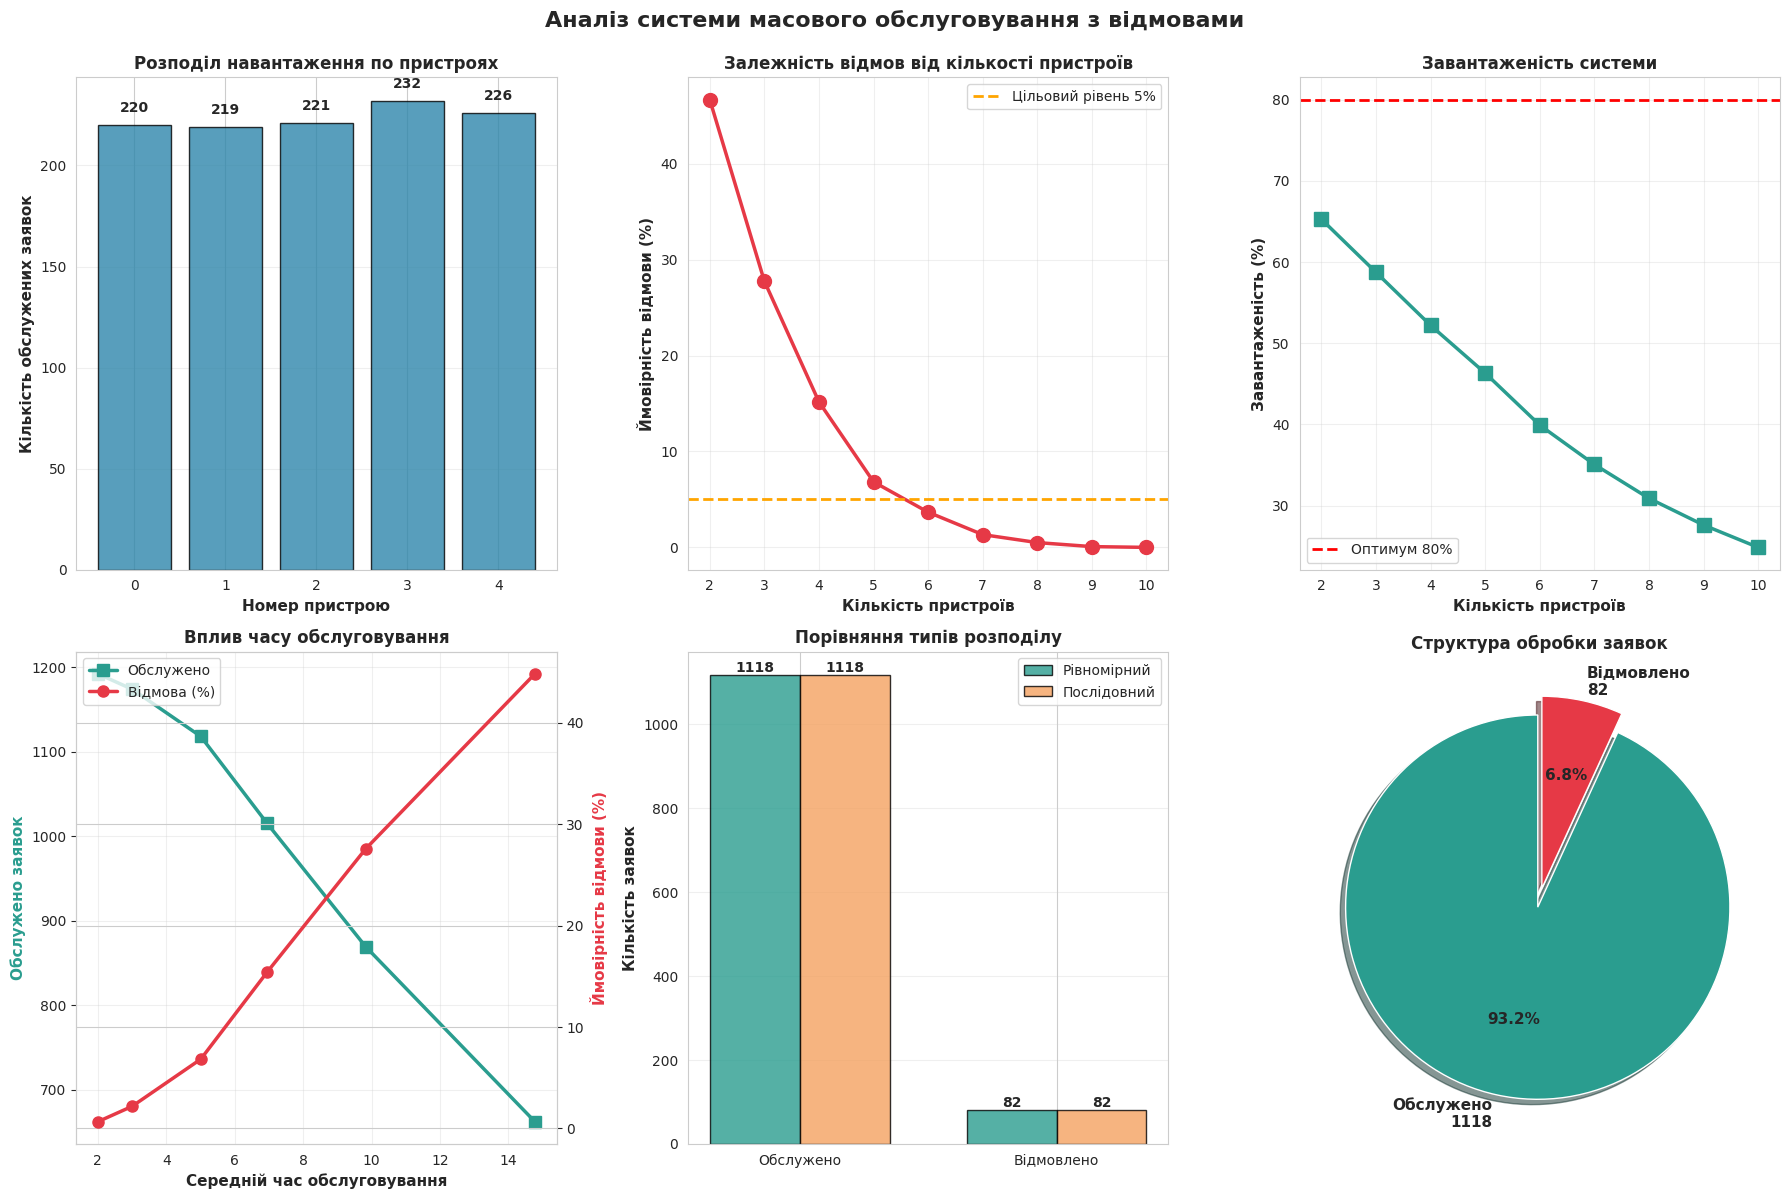

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
plt.suptitle('Аналіз системи масового обслуговування з відмовами', fontsize=16, fontweight='bold', y=0.995)

# 1. Розподіл навантаження по пристроях
axes[0, 0].bar(range(len(system.device_stats)), system.device_stats, color='#2E86AB', alpha=0.8, edgecolor='black')
axes[0, 0].set_xlabel('Номер пристрою', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Кількість обслужених заявок', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Розподіл навантаження по пристроях', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(system.device_stats):
    axes[0, 0].text(i, v + 5, str(v), ha='center', va='bottom', fontweight='bold')

# 2. Вплив кількості пристроїв
axes[0, 1].plot(df_devices_impact['Пристроїв'], df_devices_impact['Ймовірність відмови (%)'], 
                marker='o', linewidth=2.5, markersize=10, color='#E63946')
axes[0, 1].axhline(y=5, color='orange', linestyle='--', linewidth=2, label='Цільовий рівень 5%')
axes[0, 1].set_xlabel('Кількість пристроїв', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Ймовірність відмови (%)', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Залежність відмов від кількості пристроїв', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Завантаженість пристроїв
axes[0, 2].plot(df_devices_impact['Пристроїв'], df_devices_impact['Завантаженість (%)'], 
                marker='s', linewidth=2.5, markersize=10, color='#2A9D8F')
axes[0, 2].axhline(y=80, color='red', linestyle='--', linewidth=2, label='Оптимум 80%')
axes[0, 2].set_xlabel('Кількість пристроїв', fontsize=11, fontweight='bold')
axes[0, 2].set_ylabel('Завантаженість (%)', fontsize=11, fontweight='bold')
axes[0, 2].set_title('Завантаженість системи', fontsize=12, fontweight='bold')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# 4. Вплив часу обслуговування
ax4_1 = axes[1, 0]
ax4_2 = ax4_1.twinx()

line1 = ax4_1.plot(df_service_impact['Середній час обслуговування'], 
                    df_service_impact['Обслужено'],
                    marker='s', linewidth=2.5, markersize=8, color='#2A9D8F', label='Обслужено')
line2 = ax4_2.plot(df_service_impact['Середній час обслуговування'], 
                    df_service_impact['Ймовірність відмови (%)'],
                    marker='o', linewidth=2.5, markersize=8, color='#E63946', label='Відмова (%)')

ax4_1.set_xlabel('Середній час обслуговування', fontsize=11, fontweight='bold')
ax4_1.set_ylabel('Обслужено заявок', fontsize=11, fontweight='bold', color='#2A9D8F')
ax4_2.set_ylabel('Ймовірність відмови (%)', fontsize=11, fontweight='bold', color='#E63946')
ax4_1.set_title('Вплив часу обслуговування', fontsize=12, fontweight='bold')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax4_1.legend(lines, labels, loc='upper left')
ax4_1.grid(True, alpha=0.3)

# 5. Порівняння типів розподілу
categories = ['Обслужено', 'Відмовлено']
uniform_data = [df_distribution.iloc[0]['Обслужено'], df_distribution.iloc[0]['Відмовлено']]
sequential_data = [df_distribution.iloc[1]['Обслужено'], df_distribution.iloc[1]['Відмовлено']]

x = np.arange(len(categories))
width = 0.35

bars1 = axes[1, 1].bar(x - width/2, uniform_data, width, label='Рівномірний', color='#2A9D8F', alpha=0.8, edgecolor='black')
bars2 = axes[1, 1].bar(x + width/2, sequential_data, width, label='Послідовний', color='#F4A261', alpha=0.8, edgecolor='black')

axes[1, 1].set_ylabel('Кількість заявок', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Порівняння типів розподілу', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(categories)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Додаємо значення на стовпчики
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1, 1].text(bar.get_x() + bar.get_width()/2., height,
                        f'{int(height)}',
                        ha='center', va='bottom', fontsize=10, fontweight='bold')

# 6. Pie chart - структура результатів
sizes = [result['Обслужено'], result['Відмовлено']]
labels_pie = [f"Обслужено\n{result['Обслужено']}", f"Відмовлено\n{result['Відмовлено']}"]
colors_pie = ['#2A9D8F', '#E63946']
explode = (0.05, 0.05)

axes[1, 2].pie(sizes, explode=explode, labels=labels_pie, colors=colors_pie, autopct='%1.1f%%',
               shadow=True, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1, 2].set_title('Структура обробки заявок', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### Покрокове виконання моделі

#### 7. Детальне логування перших заявок


In [9]:
logger.info("ПОКРОКОВЕ ВИКОНАННЯ МОДЕЛІ (перші 30 заявок)")

result_debug, system_debug = simulate_queueing_system(
    num_devices=5,
    total_requests=30,  # Обмежуємо для наочності
    interarrival_time_mean=2.0,
    service_time_mean=5.0,
    distribution_type='uniform',
    debug=True,  # Увімкнути детальне логування
    seed=42
)

ПОКРОКОВЕ ВИКОНАННЯ МОДЕЛІ (перші 30 заявок)
t=4.81 | Заявка #1 | ПРИБУТТЯ
t=4.81 | Заявка #1 | ПРИЙНЯТО на пристрій 1
t=4.81 | Заявка #1 | ПОЧАТОК обслуговування на пристрої 1
t=5.64 | Заявка #1 | ЗАВЕРШЕНО обслуговування на пристрої 1
t=9.48 | Заявка #2 | ПРИБУТТЯ
t=9.48 | Заявка #2 | ПРИЙНЯТО на пристрій 2
t=9.48 | Заявка #2 | ПОЧАТОК обслуговування на пристрої 2
t=9.91 | Заявка #2 | ЗАВЕРШЕНО обслуговування на пристрої 2
t=14.25 | Заявка #3 | ПРИБУТТЯ
t=14.25 | Заявка #3 | ПРИЙНЯТО на пристрій 3
t=14.25 | Заявка #3 | ПОЧАТОК обслуговування на пристрої 3
t=14.52 | Заявка #3 | ЗАВЕРШЕНО обслуговування на пристрої 3
t=14.81 | Заявка #4 | ПРИБУТТЯ
t=14.81 | Заявка #4 | ПРИЙНЯТО на пристрій 2
t=14.81 | Заявка #4 | ПОЧАТОК обслуговування на пристрої 2
t=14.98 | Заявка #5 | ПРИБУТТЯ
t=14.98 | Заявка #5 | ПРИЙНЯТО на пристрій 0
t=14.98 | Заявка #5 | ПОЧАТОК обслуговування на пристрої 0
t=17.89 | Заявка #6 | ПРИБУТТЯ
t=17.89 | Заявка #6 | ПРИЙНЯТО на пристрій 4
t=17.89 | Заявка #6 | ПОЧАТОК

#### 8. Таблиця подій (Event Log)


In [10]:
event_log_df = pd.DataFrame(system_debug.events_log)

# Додаємо читабельні описи
event_names = {
    'arrival': 'Прибуття',
    'accepted': 'Прийнято',
    'rejected': 'Відмовлено',
    'service_start': 'Початок обслуг.',
    'service_end': 'Завершено'
}

event_log_df['Тип події'] = event_log_df['type'].map(event_names)
event_log_df['Час'] = event_log_df['time']
event_log_df['Заявка'] = event_log_df['request_id']
event_log_df['Пристрій'] = event_log_df['device_id'].apply(lambda x: f'Пристрій {x}' if pd.notna(x) else '-')

# Виводимо перші 50 подій
logger.info("ЖУРНАЛ ПОДІЙ (перші 50):")
display_df = event_log_df[['Час', 'Заявка', 'Тип події', 'Пристрій']].head(50)
print(display_df.to_markdown(index=False))


ЖУРНАЛ ПОДІЙ (перші 50):
|   Час |   Заявка | Тип події       | Пристрій     |
|------:|---------:|:----------------|:-------------|
|  4.81 |        1 | Прибуття        | -            |
|  4.81 |        1 | Прийнято        | Пристрій 1.0 |
|  4.81 |        1 | Початок обслуг. | Пристрій 1.0 |
|  5.64 |        1 | Завершено       | Пристрій 1.0 |
|  9.48 |        2 | Прибуття        | -            |
|  9.48 |        2 | Прийнято        | Пристрій 2.0 |
|  9.48 |        2 | Початок обслуг. | Пристрій 2.0 |
|  9.91 |        2 | Завершено       | Пристрій 2.0 |
| 14.25 |        3 | Прибуття        | -            |
| 14.25 |        3 | Прийнято        | Пристрій 3.0 |
| 14.25 |        3 | Початок обслуг. | Пристрій 3.0 |
| 14.52 |        3 | Завершено       | Пристрій 3.0 |
| 14.81 |        4 | Прибуття        | -            |
| 14.81 |        4 | Прийнято        | Пристрій 2.0 |
| 14.81 |        4 | Початок обслуг. | Пристрій 2.0 |
| 14.98 |        5 | Прибуття        | -            |
| 1

#### 9. Візуалізація часової діаграми подій


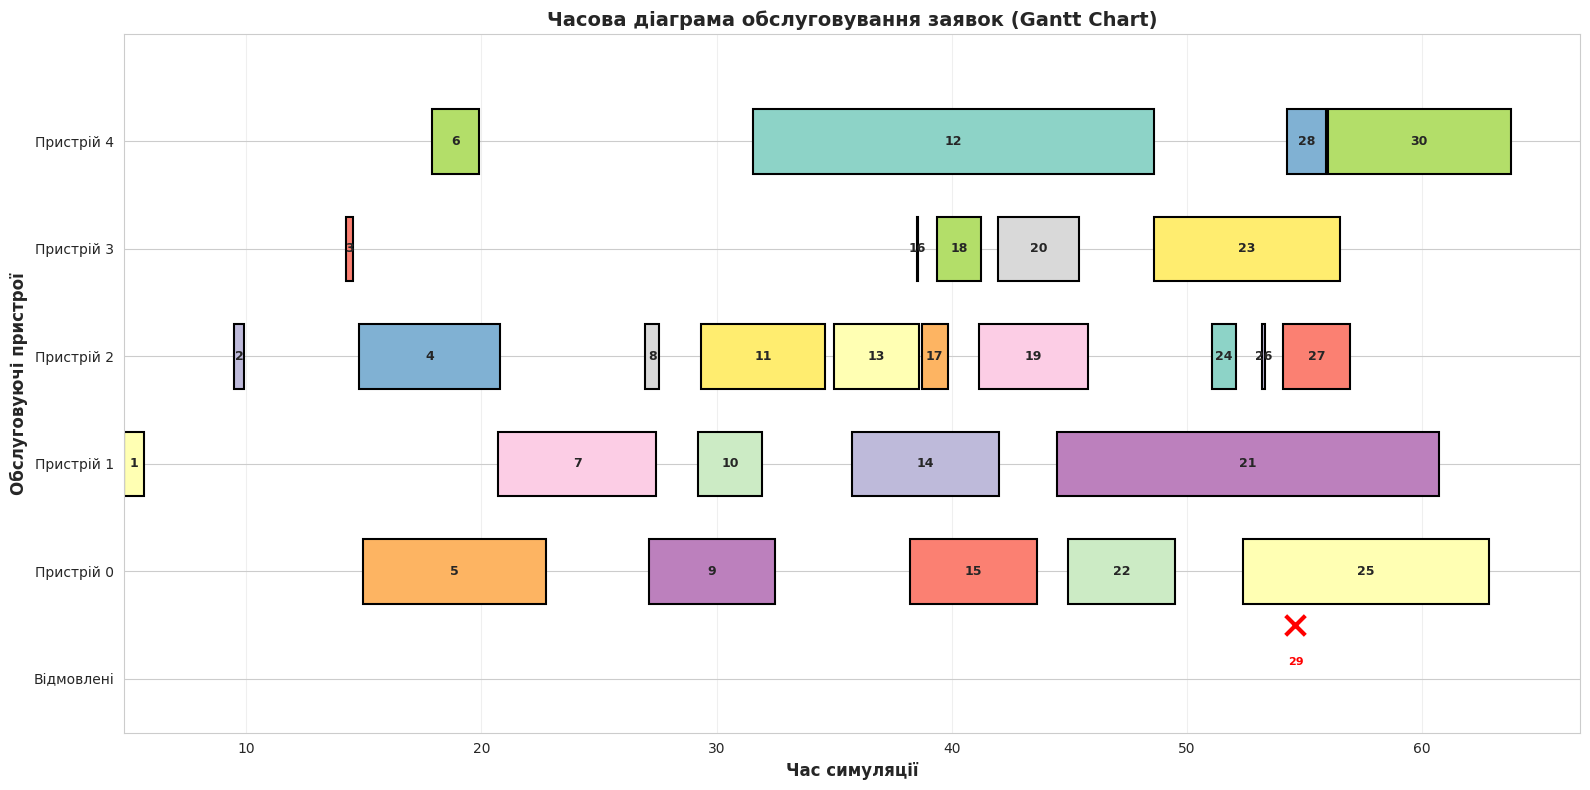

In [11]:
# Часова діаграма подій
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

# Фільтруємо події для візуалізації
service_starts = event_log_df[event_log_df['type'] == 'service_start']
service_ends = event_log_df[event_log_df['type'] == 'service_end']
rejected = event_log_df[event_log_df['type'] == 'rejected']

# Групуємо за пристроями для візуалізації як горизонтальні смуги
for device_id in range(5):
    device_services = []
    
    # Знаходимо всі пари start-end для цього пристрою
    starts = service_starts[service_starts['device_id'] == device_id].sort_values('time')
    ends = service_ends[service_ends['device_id'] == device_id].sort_values('time')
    
    for _, start_event in starts.iterrows():
        request_id = start_event['request_id']
        start_time = start_event['time']
        
        # Знаходимо відповідний end
        end_event = ends[ends['request_id'] == request_id]
        if not end_event.empty:
            end_time = end_event.iloc[0]['time']
            duration = end_time - start_time
            
            # Малюємо горизонтальну смугу
            ax.barh(device_id, duration, left=start_time, height=0.6, 
                   color=plt.cm.Set3(request_id % 12), edgecolor='black', linewidth=1.5)
            
            # Додаємо номер заявки
            ax.text(start_time + duration/2, device_id, f'{int(request_id)}', 
                   ha='center', va='center', fontsize=9, fontweight='bold')

# Додаємо відмовлені заявки як червоні хрестики
if not rejected.empty:
    for _, rej_event in rejected.iterrows():
        ax.scatter(rej_event['time'], -0.5, color='red', marker='x', s=200, linewidths=3, zorder=10)
        ax.text(rej_event['time'], -0.8, f"{int(rej_event['request_id'])}", 
               ha='center', va='top', fontsize=8, color='red', fontweight='bold')

ax.set_yticks(range(-1, 5))
ax.set_yticklabels(['Відмовлені'] + [f'Пристрій {i}' for i in range(5)])
ax.set_xlabel('Час симуляції', fontsize=12, fontweight='bold')
ax.set_ylabel('Обслуговуючі пристрої', fontsize=12, fontweight='bold')
ax.set_title('Часова діаграма обслуговування заявок (Gantt Chart)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
ax.set_ylim(-1.5, 5)

plt.tight_layout()
plt.show()

### Висновки та аналіз результатів

#### 10. Характеристика отриманих результатів


In [12]:
logger.info("ВИСНОВКИ")

logger.info(f"""\nОСНОВНІ РЕЗУЛЬТАТИ МОДЕЛЮВАННЯ:
Всього згенеровано заявок: {result['Прибуло заявок']}
Успішно обслужено: {result['Обслужено']} ({result['Обслужено']/result['Прибуло заявок']*100:.1f}%)
Відмовлено у обслуговуванні: {result['Відмовлено']} ({result['Ймовірність відмови (%)']}%)
Завантаженість системи: {result['Завантаженість (%)']}%""")

logger.info(f"""\nВПЛИВ ПАРАМЕТРІВ:
При збільшенні кількості пристроїв з 2 до 10:
Ймовірність відмови зменшується з {df_devices_impact.iloc[0]['Ймовірність відмови (%)']}% до {df_devices_impact.iloc[-1]['Ймовірність відмови (%)']}%
Завантаженість змінюється з {df_devices_impact.iloc[0]['Завантаженість (%)']}% до {df_devices_impact.iloc[-1]['Завантаженість (%)']}%
При збільшенні часу обслуговування:
Ймовірність відмови зростає (система перевантажується)
Кількість обслужених заявок зменшується""")

uniform_rejected = df_distribution.iloc[0]['Відмовлено']
sequential_rejected = df_distribution.iloc[1]['Відмовлено']
logger.info(f"""\nПОРІВНЯННЯ ТИПІВ РОЗПОДІЛУ:
Рівномірний розподіл: {uniform_rejected} відмов
Послідовний розподіл: {sequential_rejected} відмов""")
if uniform_rejected < sequential_rejected:
    logger.info(f"Рівномірний розподіл ефективніший на {sequential_rejected - uniform_rejected} заявок")
else:
    logger.info("Розподіли показують подібну ефективність")

optimal_devices = df_devices_impact[df_devices_impact['Ймовірність відмови (%)'] < 5]['Пристроїв'].min()
optimal_utilization = df_devices_impact[df_devices_impact['Пристроїв'] == optimal_devices]['Завантаженість (%)'].values[0]
logger.info(f"""\nРЕКОМЕНДАЦІЇ:
Для досягнення ймовірності відмови < 5% потрібно мінімум {optimal_devices} пристроїв
При {optimal_devices} пристроях завантаженість становить {optimal_utilization}%
Для досягнення балансу між витратами та якістю обслуговування
рекомендується використовувати {optimal_devices} пристроїв""")

logger.info(f"""\nПЕРЕВІРКА ПРАВИЛЬНОСТІ АЛГОРИТМУ:
Покрокове виконання підтверджує коректність моделі:
Заявки генеруються з правильним інтервалом (експоненціальний розподіл)
Розподіл працює згідно з вибраною стратегією ({'рівномірний' if distribution_type == 'uniform' else 'послідовний'})
При зайнятості всіх пристроїв заявки коректно відхиляються
Час обслуговування відповідає експоненціальному розподілу
Завантаженість пристроїв розподілена {'рівномірно' if max(system.device_stats) - min(system.device_stats) < 50 else 'нерівномірно'}""")

ВИСНОВКИ

ОСНОВНІ РЕЗУЛЬТАТИ МОДЕЛЮВАННЯ:
Всього згенеровано заявок: 1200
Успішно обслужено: 1118 (93.2%)
Відмовлено у обслуговуванні: 82 (6.83%)
Завантаженість системи: 46.32%

ВПЛИВ ПАРАМЕТРІВ:
При збільшенні кількості пристроїв з 2 до 10:
Ймовірність відмови зменшується з 46.67% до 0.0%
Завантаженість змінюється з 65.27% до 24.86%
При збільшенні часу обслуговування:
Ймовірність відмови зростає (система перевантажується)
Кількість обслужених заявок зменшується

ПОРІВНЯННЯ ТИПІВ РОЗПОДІЛУ:
Рівномірний розподіл: 82 відмов
Послідовний розподіл: 82 відмов
Розподіли показують подібну ефективність

РЕКОМЕНДАЦІЇ:
Для досягнення ймовірності відмови < 5% потрібно мінімум 6 пристроїв
При 6 пристроях завантаженість становить 39.91%
Для досягнення балансу між витратами та якістю обслуговування
рекомендується використовувати 6 пристроїв

ПЕРЕВІРКА ПРАВИЛЬНОСТІ АЛГОРИТМУ:
Покрокове виконання підтверджує коректність моделі:
Заявки генеруються з правильним інтервалом (експоненціальний розподіл)
Розп